# Module 03 — Weight Initialization, Activations, and Residual Scaling

This notebook studies how initialization scale, residual branches, and normalization affect activations before and during training.

## 1. Xavier and Kaiming initialization

These initializers choose weight scale using layer dimensions and activation assumptions.

In [1]:
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

torch.manual_seed(42)

xavier_layer = nn.Linear(128, 256)
nn.init.xavier_normal_(xavier_layer.weight)
nn.init.zeros_(xavier_layer.bias)

kaiming_layer = nn.Linear(128, 256)
nn.init.kaiming_normal_(
    kaiming_layer.weight,
    mode="fan_in",
    nonlinearity="relu",
)
nn.init.zeros_(kaiming_layer.bias)

print("Xavier std:", xavier_layer.weight.std().item())
print("Kaiming std:", kaiming_layer.weight.std().item())

Xavier std: 0.07276137918233871
Kaiming std: 0.12512268126010895


## 2. Activation scale through depth

The linear stack isolates the effect of initialization scale.

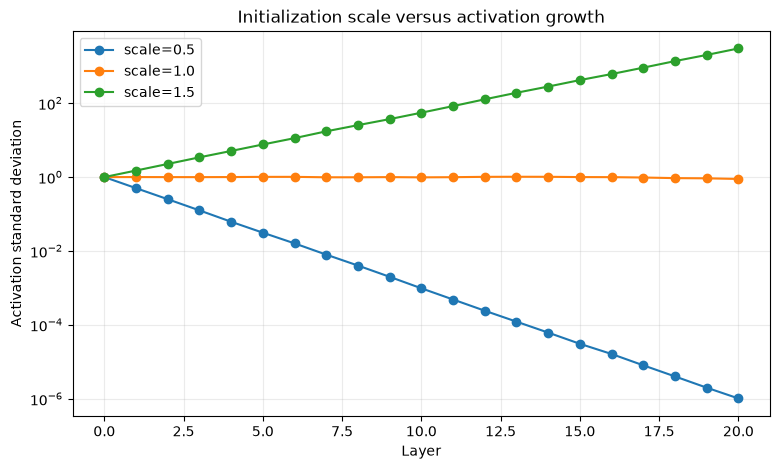

In [2]:
def run_experiment(scale, depth=20, dim=128):
    layers = []
    for _ in range(depth):
        layer = nn.Linear(dim, dim, bias=False)
        nn.init.normal_(
            layer.weight,
            mean=0.0,
            std=scale / (dim ** 0.5),
        )
        layers.append(layer)

    x = torch.randn(256, dim)
    stds = [x.std().item()]
    with torch.no_grad():
        for layer in layers:
            x = layer(x)
            stds.append(x.std().item())
    return stds


plt.figure(figsize=(9, 5))
for scale in (0.5, 1.0, 1.5):
    values = run_experiment(scale)
    plt.plot(
        range(len(values)),
        values,
        marker="o",
        label=f"scale={scale}",
    )

plt.yscale("log")
plt.xlabel("Layer")
plt.ylabel("Activation standard deviation")
plt.title("Initialization scale versus activation growth")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

## 3. Residual branch scaling

Use identical underlying weights so the comparison isolates `alpha`.

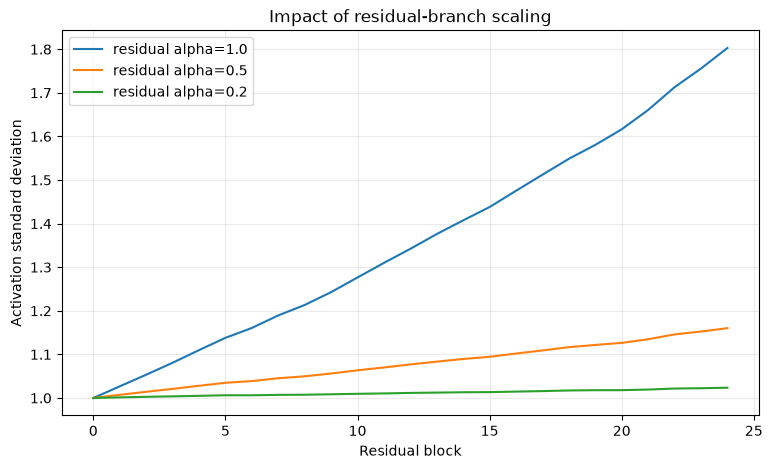

In [3]:
class ResidualStack(nn.Module):
    def __init__(self, weight_templates, alpha=1.0):
        super().__init__()
        self.layers = nn.ModuleList(
            [nn.Linear(128, 128, bias=False) for _ in weight_templates]
        )
        for layer, template in zip(self.layers, weight_templates):
            with torch.no_grad():
                layer.weight.copy_(template)
        self.alpha = alpha

    def forward(self, x):
        stds = [x.std().item()]
        for layer in self.layers:
            x = x + self.alpha * layer(x)
            stds.append(x.std().item())
        return stds


base_layers = []
for _ in range(24):
    weight = torch.empty(128, 128)
    nn.init.normal_(weight, std=0.02)
    base_layers.append(weight)

x = torch.randn(256, 128)
plt.figure(figsize=(9, 5))
for alpha in (1.0, 0.5, 0.2):
    model = ResidualStack(base_layers, alpha=alpha)
    values = model(x.clone())
    plt.plot(
        range(len(values)),
        values,
        label=f"residual alpha={alpha}",
    )

plt.xlabel("Residual block")
plt.ylabel("Activation standard deviation")
plt.title("Impact of residual-branch scaling")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

## 4. RMSNorm calculation

This small calculation shows what RMSNorm does to a single vector before the learned scale is applied.

In [4]:
hidden = torch.tensor([2.0, 4.0, 6.0, 8.0])
rms = hidden.square().mean().sqrt()
normalized = hidden / rms

print("Input:", hidden)
print("RMS:", rms.item())
print("Normalized:", normalized)
print("Output RMS:", normalized.square().mean().sqrt().item())

Input: tensor([2., 4., 6., 8.])
RMS: 5.4772257804870605
Normalized: tensor([0.3651, 0.7303, 1.0954, 1.4606])
Output RMS: 0.9999999403953552


## 5. Inspect parameters before training

Use this report before a long run to catch unexpected scale or non-finite values.

In [5]:
def inspect_parameters(model):
    for name, parameter in model.named_parameters():
        if not parameter.requires_grad:
            continue

        values = parameter.detach().float()
        print(
            name,
            "shape:", tuple(values.shape),
            "mean:", round(values.mean().item(), 5),
            "std:", round(values.std(unbiased=False).item(), 5),
            "max_abs:", round(values.abs().max().item(), 5),
            "finite:", torch.isfinite(values).all().item(),
        )


inspect_model = nn.Sequential(
    nn.Linear(128, 256),
    nn.LayerNorm(256),
    nn.Linear(256, 128),
)
inspect_parameters(inspect_model)

0.weight shape: (256, 128) mean: 0.00033 std: 0.05119 max_abs: 0.08839 finite: True
0.bias shape: (256,) mean: 0.00229 std: 0.04987 max_abs: 0.08832 finite: True
1.weight shape: (256,) mean: 1.0 std: 0.0 max_abs: 1.0 finite: True
1.bias shape: (256,) mean: 0.0 std: 0.0 max_abs: 0.0 finite: True
2.weight shape: (128, 256) mean: -0.00036 std: 0.03611 max_abs: 0.0625 finite: True
2.bias shape: (128,) mean: 0.00267 std: 0.03528 max_abs: 0.06239 finite: True


## Exercises

1. Change `depth=20` to `depth=50` in the activation experiment.
2. Compare ReLU and tanh after Xavier and Kaiming initialization.
3. Add an RMSNorm operation inside the residual stack and compare activation scales.
4. Record gradient norms after one backward pass, not only activation standard deviations.